# Step 7c: Candidate 3 of 4, XGBoost with the Tweedie objective

Same rules as before: winner by **R² in £** (MAE breaks ties), **5-fold CV on train only**, **250 Optuna trials**, features **R, F, M**, **test not touched**.

## What is different from 7b?
Same boosted trees, but a different **loss function** (what the model tries to minimise). 7b minimised squared error in £. Tweedie assumes the target looks like "many exact zeros plus a long right tail", which is exactly what our 6-month spend looks like.

- **Predictions are never negative.** The trees work on a log scale internally and the model predicts `exp(score)`.
- **Errors are weighted relative to the size of the customer** instead of every £ counting the same, so the giants dominate the loss less.

## What Optuna tunes (the five settings from 7b plus one)
| Setting | Meaning | Range |
|---|---|---|
| `n_estimators` | number of trees | 50 to 500 |
| `max_depth` | how deep each tree can go | 2 to 6 |
| `learning_rate` | size of each tree's correction | 0.01 to 0.3 (log) |
| `subsample` | share of customers each tree sees | 0.3 to 1.0 |
| `colsample_bytree` | share of features each tree sees | 0.5 to 1.0 |
| **`tweedie_variance_power`** | how the model treats zeros and spread: near 1 = count-like, zero-friendly; near 2 = heavy-tailed positive amounts | 1.01 to 1.99 |

Code: `src/step7c_tweedie.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from metrics import r2
from step3_split import load_ledger, make_snapshot, TRAIN_CUTOFF
from step4_rfm import build_rfm
from step6_baselines import BASELINES, cv_predictions, score_table
from step7a_ridge_log import LogRidge
from step7b_xgboost import XGBModel, oof_with_seed
from step7c_tweedie import XGBTweedie, suggest_tweedie, N_TRIALS, ALPHA_7A_SMEAR, BEST_7B
from tuning import tune

pd.set_option("display.width", 200)
train = make_snapshot(load_ledger(), TRAIN_CUTOFF)
X, y = build_rfm(train), train.target
ya = y.to_numpy()

/data/home/mitanshub/miniconda3/envs/ml_clv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Tune with Optuna

{'n_estimators': 395, 'max_depth': 2, 'learning_rate': 0.0141, 'subsample': 0.9957, 'colsample_bytree': 0.7604, 'tweedie_variance_power': 1.5677}
best CV R2 (tuning score): 0.508


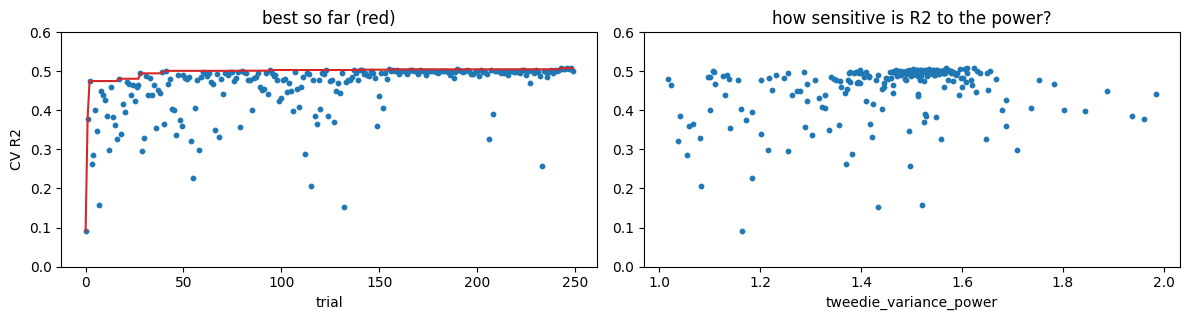

In [2]:
study = tune(lambda **p: XGBTweedie(**p), suggest_tweedie, X, y, n_trials=N_TRIALS)
best = study.best_params
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in best.items()})
print(f"best CV R2 (tuning score): {study.best_value:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.3))
vals = [t.value for t in study.trials]
axes[0].scatter(range(len(vals)), vals, s=10); axes[0].plot(np.maximum.accumulate(vals), color="tab:red")
axes[0].set_ylim(0, 0.6); axes[0].set_xlabel("trial"); axes[0].set_ylabel("CV R2"); axes[0].set_title("best so far (red)")
axes[1].scatter([t.params["tweedie_variance_power"] for t in study.trials], vals, s=10)
axes[1].set_ylim(0, 0.6); axes[1].set_xlabel("tweedie_variance_power"); axes[1].set_title("how sensitive is R2 to the power?")
plt.tight_layout()

The best settings are **simple**: 395 very shallow trees (depth 2), a small learning rate, and a variance power of about 1.57 (between count-like and heavy-tailed). Two settings sit at the edge of their ranges: `max_depth` 2 (the minimum allowed) and `subsample` 0.996 (the maximum). Depth 2 at the minimum means even simpler trees (depth 1) might do as well; the model does not want complexity.

## 2. Compare (train CV)

In [3]:
preds = {n: cv_predictions(c, X, y) for n, c in BASELINES.items()}
preds["LogRidge + smearing (7a)"] = cv_predictions(lambda: LogRidge(ALPHA_7A_SMEAR, True), X, y)
preds["XGBoost raw GBP (7b)"] = cv_predictions(lambda: XGBModel(**BEST_7B), X, y)
preds["XGBoost Tweedie (7c)"] = cv_predictions(lambda: XGBTweedie(**best), X, y)

t = score_table(ya, preds)
t["total pred / total actual"] = [preds[k].sum() / ya.sum() for k in t.index]
display(t.round(3))
print("Same, without the 10 biggest customers:")
display(score_table(ya, preds, without_top=10).round(3))

,R2,MAE,Capture@20%,total pred / total actual
mean,-0.000,944.129,0.170,1.000
past_spend,0.746,523.153,0.739,1.001
LogRidge + smearing (7a),0.549,575.161,0.722,0.992
XGBoost raw GBP (7b),0.503,600.542,0.711,1.001
XGBoost Tweedie (7c),0.508,534.231,0.744,0.922


Same, without the 10 biggest customers:


,R2,MAE,Capture@20%
mean,-0.006,821.868,0.186
past_spend,0.549,471.154,0.686
LogRidge + smearing (7a),0.500,498.504,0.666
XGBoost raw GBP (7b),0.322,532.080,0.650
XGBoost Tweedie (7c),0.538,464.279,0.691


Honest-estimate check, as in 7b: the same settings on 10 *other* fold splits.

In [4]:
rs = [r2(ya, oof_with_seed(lambda: XGBTweedie(**best), X, y, s)) for s in range(10)]
print(f"R2 on 10 other fold splits: mean {np.mean(rs):.3f}, sd {np.std(rs):.3f}, range {min(rs):.3f} to {max(rs):.3f}")
print(f"tuning score on the fold split Optuna saw: {study.best_value:.3f}")

R2 on 10 other fold splits: mean 0.487, sd 0.013, range 0.471 to 0.520
tuning score on the fold split Optuna saw: 0.508


The tuning score (0.508) is a little optimistic; the honest estimate is about **0.49**. That is a smaller gap than 7b had (0.503 vs 0.478), probably because Tweedie settled on a simple model.

## 3. The three metrics disagree: why?

Tweedie is the best model on **MAE** (534; 7b 600; 7a 575) and ties past spend on **ranking** (0.744 vs 0.739), but its **R²** (0.51) is not the highest. R² and MAE look at different customers: MAE is the *typical* miss, R² is dominated by the *giants*. Look at the biggest customers:

In [5]:
d = pd.DataFrame({"Monetary": X["Monetary"], "actual": ya, "past_spend": preds["past_spend"],
                  "Ridge+smear": preds["LogRidge + smearing (7a)"], "XGB raw": preds["XGBoost raw GBP (7b)"],
                  "Tweedie": preds["XGBoost Tweedie (7c)"]})
display(d.nlargest(6, "Monetary").round(0))
print(f"largest Tweedie prediction: {preds['XGBoost Tweedie (7c)'].max():,.0f} | largest actual: {ya.max():,.0f}")
top = np.argsort(-ya)[:10]
for n in ("past_spend", "LogRidge + smearing (7a)", "XGBoost raw GBP (7b)", "XGBoost Tweedie (7c)"):
    e = (ya - preds[n]) ** 2
    print(f"{n:26s} share of squared error from the 10 biggest actual customers: {e[top].sum() / e.sum():.0%}")

,Monetary,actual,past_spend,Ridge+smear,XGB raw,Tweedie
Customer ID,,,,,,
18102,318751.0,92477.0,120142.0,37841.0,32065.0,31740.0
14646,245028.0,110668.0,89681.0,52982.0,30255.0,23076.0
14156,185106.0,41661.0,70210.0,41658.0,43054.0,37766.0
14911,132744.0,38486.0,48251.0,79059.0,28901.0,39426.0
13694,127430.0,27171.0,48334.0,34923.0,43194.0,37766.0
17511,80366.0,38871.0,29414.0,12007.0,18009.0,15695.0


largest Tweedie prediction: 39,426 | largest actual: 110,668
past_spend                 share of squared error from the 10 biggest actual customers: 55%
LogRidge + smearing (7a)   share of squared error from the 10 biggest actual customers: 72%
XGBoost raw GBP (7b)       share of squared error from the 10 biggest actual customers: 66%
XGBoost Tweedie (7c)       share of squared error from the 10 biggest actual customers: 76%


Tweedie is still a tree model, so it **still cannot predict the giants** (its largest prediction is about £39k, real spend reaches £110k, and 76% of its squared error comes from the 10 biggest customers). That caps its R². But for the other ~4,200 customers it is the best model of all, which is why its MAE is the best and why, **without the 10 biggest customers, its R² (0.54) is on par with past spend (0.55) and far above 7b (0.32)**.

Tweedie also **under-predicts the total by 8%** (0.92), while 7b is spot on and 7a smearing is within 1%.

## 4. What it relies on

In [6]:
imp = pd.Series(XGBTweedie(**best).fit(X, y).model_.feature_importances_, index=X.columns)
imp.round(3).to_frame("importance")

,importance
Recency,0.056
Frequency,0.421
Monetary,0.523


Monetary (0.52) and Frequency (0.42) again, with a small role for Recency (0.06).

## What we learned

| Train CV | R² | MAE (£) | Capture@20% | total pred / total actual | R² without top 10 |
|---|---|---|---|---|---|
| mean | 0.00 | 944 | 0.17 | 1.00 | -0.01 |
| **past_spend** | **0.75** | 523 | 0.74 | 1.00 | **0.55** |
| Ridge on log1p + smearing (7a) | 0.55 | 575 | 0.72 | 0.99 | 0.50 |
| XGBoost raw £ (7b) | 0.50 (honest 0.48) | 600 | 0.71 | 1.00 | 0.32 |
| **XGBoost Tweedie (7c)** | 0.51 (honest 0.49) | **534** | **0.74** | 0.92 | 0.54 |

- **By our rule (R² picks the winner), past spend still leads**, and among the models Ridge + smearing (0.55) is ahead of Tweedie (0.51).
- **Tweedie is the best model on MAE and on ranking**, and on par with past spend once the 10 giants are removed. It is the first candidate that is competitive with the spreadsheet rule for the typical customer.
- **Its weakness is the same as 7b's:** trees cannot predict the giants (largest prediction about £39k vs £110k actual). That is what keeps its R² near 0.5.
- The Tweedie loss fixed a lot of 7b's problems (MAE 600 to 534, R² without the giants 0.32 to 0.54) just by describing the target's shape better.
- It under-predicts the total by 8%, a small calibration cost.

**Next (step 7d):** the Hurdle model, which splits the problem in two: "will they buy at all?" and "how much, if they do?".